### CNN 및 DROPOUT

## STL-10 Dataset
: 자연 및 인공 사물 이미지를 10개 클래스로 분류하는 이미지 데이터셋

- 학습데이터 : 5,000장 (라벨 데이터)
- 테스트 데이터 : 8,000장
- 비라벨 학습데이터 : 100,000장
- 원본 이미지 크기 : 96 × 96 (컬러 이미지)
- 입력 데이터: RGB 이미지 (64 × 64로 크기 변경)
- 입력 특징 수: 3 × 64 × 64 = 3,072
- 출력 클래스: 10개
- 다운로드 : `split="train"`과 `split="test"`를 구분하여 다운로드
- 모델은 CNN_drop (p=0.3), CNN_deep_drop (p=0.3) 2가지를 정의하여 사용

| 클래스 이름 | 의미 |
|:---:|:---|
| `airplane` | 비행기 |
| `bird` | 새 |
| `car` | 자동차 |
| `cat` | 고양이 |
| `deer` | 사슴 |
| `dog` | 개 |
| `horse` | 말 |
| `monkey` | 원숭이 |
| `ship` | 선박 |
| `truck` | 트럭 |

LR = 1e-3<br>
EPOCH = 10<br>
**test_DS.class_to_idx**는 기본제공되지 않음

1. 문제 1
- train, test데이터 모두 transforms는 사이즈 64 x 64 적용

2. 문제 2
- train 데이터의 transforms는
    - 사이즈 64 x 64 적용
    - 이미지의 좌우 반전을 50%의 확률로 적용
    - 입력 이미지의 상하좌우에 4픽셀씩 패딩을 추가한 후, 64×64 크기를 무작위로 잘라내기 (transforms.RandomCrop(64, padding=4))
    - Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)) 적용

- test 데이터의 transforms는
    - 사이즈 64 x 64 적용
    - Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)) 적용

**실행시 문제1과 문제2는 하나씩 선택하여 실행**

In [54]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn, optim
from torchinfo import summary
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [107]:
BATCH_SIZE = 64
LR = 1e-3
EPOCH = 15
criterion = nn.CrossEntropyLoss()
IMAGE_SIZE = 64

criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'CNN_deep_drop' # 'CNN_drop', 'CNN_deep_drop'
dataset = 'STL10'  # 'STL10', 'STL_norm'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [108]:
# 이미지 전처리 구정(autoaugment, totensor)
transform = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

transform_train = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomCrop(64, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4467, 0.4398, 0.4066),
        (0.2603, 0.2566, 0.2713)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4467, 0.4398, 0.4066),
        (0.2603, 0.2566, 0.2713)),
])

train_DS = datasets.STL10(root='data', split='train', download=True, transform=transform)
test_DS = datasets.STL10(root='data', split='test', download=True, transform=transform)

train_DS_norm = datasets.STL10(root='data', split='train', download=False, transform=transform_train)
test_DS_norm = datasets.STL10(root='data', split='test', download=False, transform=transform_test)

In [76]:
# train_DS.classes = [str(i) for i in range(10)]
# test_DS.classes = [str(i) for i in range(10)]

In [77]:
# x, y = train_DS[0]

# print('Train size :', len(train_DS))
# print('Test size  :', len(test_DS))
# print('Image shape:', x.shape)
# print('Image dtype:', x.dtype)
# print('Label      :', y)
# print('n_class    :', len(train_DS.classes))

In [109]:
split_idx = int(len(train_DS) * 0.8)

x_train = train_DS.data[:split_idx]
x_val = train_DS.data[split_idx:]

y_train = train_DS.labels[:split_idx]
y_val = train_DS.labels[split_idx:]

x_train_ts = torch.tensor(x_train, dtype=torch.float32) / 255.
x_val_ts = torch.tensor(x_val, dtype=torch.float32) / 255.

y_train_ts = torch.tensor(y_train, dtype=torch.long)
y_val_ts = torch.tensor(y_val, dtype=torch.long)

train_subset = TensorDataset(x_train_ts, y_train_ts)
val_subset = TensorDataset(x_val_ts, y_val_ts)

In [110]:
x_train_norm = train_DS_norm.data[:split_idx]
x_val_norm = train_DS_norm.data[split_idx:]

y_train_norm = train_DS_norm.labels[:split_idx]
y_val_norm = train_DS_norm.labels[split_idx:]

x_train_ts_norm = torch.tensor(x_train_norm, dtype=torch.float32) / 255.
x_val_ts_norm = torch.tensor(x_val_norm, dtype=torch.float32) / 255.

y_train_ts_norm = torch.tensor(y_train_norm, dtype=torch.long)
y_val_ts_norm = torch.tensor(y_val_norm, dtype=torch.long)

train_subset_norm = TensorDataset(x_train_ts_norm, y_train_ts_norm)
val_subset_norm = TensorDataset(x_val_ts_norm, y_val_ts_norm)

In [111]:
train_DL = DataLoader(
    train_DS,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_DL = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_DL = DataLoader(
    test_DS,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [81]:
train_DL_norm = DataLoader(
    train_DS_norm,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_DL_norm = DataLoader(
    val_subset_norm,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_DL_norm = DataLoader(
    test_DS_norm,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [82]:
# x_batch, y_batch = next(iter(train_DL))

# plt.figure(figsize=(9, 9))

# class_names = [
#     'airplane', 'bird', 'car', 'cat', 'deer',
#     'dog', 'horse', 'monkey', 'ship', 'truck'
# ]

# for i in range(9):
#     plt.subplot(3, 3, i + 1)
#     plt.imshow(x_batch[i].permute(1, 2, 0))
#     plt.title(f'Label: {class_names[y_batch[i].item()]}')
#     plt.axis('off')

# plt.tight_layout()
# plt.show()

In [ ]:
class CNN_drop(nn.Module):
    def __init__(self,*args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(3,32,3,padding=1),
                                   nn.BatchNorm2d(32),
                                   nn.ReLU(),
                                   nn.Dropout(.2)
                                   )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(nn.Conv2d(32,64,3,padding=1),
                                   nn.BatchNorm2d(64),
                                   nn.ReLU(),
                                   nn.Dropout(.2)
                                   )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(nn.Conv2d(64,128,3,padding=1),
                                   nn.BatchNorm2d(128),
                                   nn.ReLU(),
                                   nn.Dropout(.2)
                                   )
        self.maxpool3 = nn.MaxPool2d(2)
        self.adaptpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(128,10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = self.adaptpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

class CNN_deep_drop(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(3,32,3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32,32,3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Dropout(.3)
        )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(32,64,3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64,64,3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Dropout(.3)
        )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(64,128,3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128,128,3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Dropout(.3)
        )
        # self.maxpool3 = nn.MaxPool2d(2)   # 특징맵에서 위치나 모양의 차이가 분류에 중요하다면 Maxpool이 정확도를 낮출 수 있음
        self.adaptpool = nn.AdaptiveAvgPool2d((1,1))
        self.fc = nn.Linear(128,10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = self.adaptpool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [113]:
model = globals()[model_type]().to(device)

# 모델 구조 출력
# model.eval()

# x_batch, y_batch = next(iter(train_DL))
# x_batch = x_batch.to(device)

# with torch.no_grad():
#     conv1 = model.conv1(x_batch)
#     conv2 = model.conv2(model.maxpool1(conv1))
#     conv3 = model.conv3(model.maxpool2(conv2))
#     flat = torch.flatten(model.adaptpool(model.maxpool3(conv3)), start_dim=1)
#     fc = model.fc(flat)

# print('Input   :', x_batch.shape)
# print('Conv1   :', conv1.shape)
# print('Conv2   :', conv2.shape)
# print('Conv3   :', conv3.shape)
# print('Flatten :', flat.shape)
# print('Output  :', fc.shape)

In [85]:
def train(dataloader, model, loss_fn, optimizer, device):

    size = len(dataloader.dataset)

    model.train()
    rloss = 0

    for x_train_ts, y_train_ts in dataloader:
        x, y = x_train_ts.to(device), y_train_ts.to(device)

        pred = model(x)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_b = loss.item() * x.shape[0]
        rloss += loss_b

    loss_e = rloss / size

    return loss_e

In [86]:
def evaluate(dataloader, model, loss_fn, device):
    model.eval()
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x_val_ts.to(device), y_val_ts.to(device)
            pred = model(x)
            val_loss = loss_fn(pred, y).item()
    return val_loss, pred

In [87]:
def learning_curve(tr_loss_list, val_loss_list):
    epochs = list(range(1, len(tr_loss_list)+1))
    plt.plot(epochs, tr_loss_list, label='train error', marker='.')
    plt.plot(epochs, val_loss_list, label='val error', marker='.')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()
    plt.show()

Ep 1, TL 1.7273, VL 1.8982
Ep 2, TL 1.5180, VL 1.7181
Ep 3, TL 1.4132, VL 1.8484
Ep 4, TL 1.2791, VL 1.9852
Ep 5, TL 1.2021, VL 1.9089
Ep 6, TL 1.1253, VL 1.8625
Ep 7, TL 1.0731, VL 1.8204
Ep 8, TL 1.0149, VL 2.2879
Ep 9, TL 0.9795, VL 1.9407
Ep 10, TL 0.9367, VL 1.6957
Ep 11, TL 0.9060, VL 1.6264
Ep 12, TL 0.8438, VL 1.6424
Ep 13, TL 0.8027, VL 1.4165
Ep 14, TL 0.7764, VL 1.3095
Ep 15, TL 0.7681, VL 1.6046


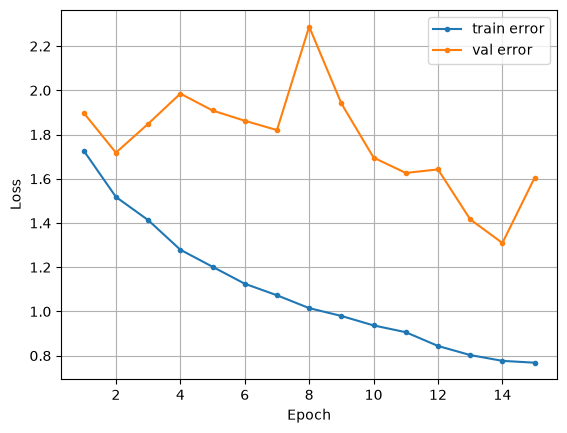

In [ ]:
# Maxpool count : 3
optimizer = optim.Adam(model.parameters(), lr=LR)
tr_loss_list, val_loss_list = [], []
if new_model_train:
    for ep in range(EPOCH):
        tr_loss = train(train_DL, model, criterion, optimizer, device)
        val_loss, _ = evaluate(val_DL, model, criterion, device)
        tr_loss_list.append(tr_loss)
        val_loss_list.append(val_loss)
        print(f'Ep {ep+1:2d}, TL {tr_loss:.4f}, VL {val_loss:.4f}')

    torch.save(model, save_model_path)
    learning_curve(tr_loss_list, val_loss_list)


In [ ]:
# Maxpool count : 2
optimizer = optim.Adam(model.parameters(), lr=LR)
tr_loss_list, val_loss_list = [], []
if new_model_train:
    for ep in range(EPOCH):
        tr_loss = train(train_DL, model, criterion, optimizer, device)
        val_loss, _ = evaluate(val_DL, model, criterion, device)
        tr_loss_list.append(tr_loss)
        val_loss_list.append(val_loss)
        print(f'Ep {ep+1:2d}, TL {tr_loss:.4f}, VL {val_loss:.4f}')

    torch.save(model.state_dict(), save_model_path)
    learning_curve(tr_loss_list, val_loss_list)

Ep 1, TL 1.8191, VL 2.5488
Ep 2, TL 1.6116, VL 2.5878
Ep 3, TL 1.5059, VL 2.5814
Ep 4, TL 1.4403, VL 2.6679
Ep 5, TL 1.4023, VL 2.6398
Ep 6, TL 1.3513, VL 2.6960
Ep 7, TL 1.3110, VL 3.0101
Ep 8, TL 1.3193, VL 2.6885
Ep 9, TL 1.2704, VL 2.6581
Ep 10, TL 1.2502, VL 2.8831
Ep 11, TL 1.2340, VL 3.0101
Ep 12, TL 1.2162, VL 2.8562
Ep 13, TL 1.1936, VL 3.0408
Ep 14, TL 1.1749, VL 2.9566
Ep 15, TL 1.1632, VL 2.9612


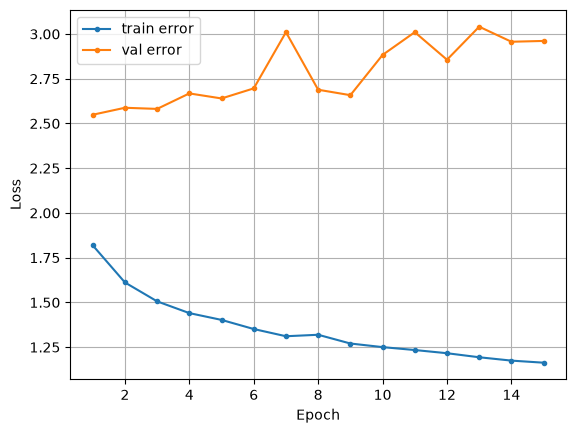

In [ ]:
# # Normalized datasets
# optimizer = optim.Adam(model.parameters(), lr=LR)
# tr_loss_list, val_loss_list = [], []
# if new_model_train:
#     for ep in range(EPOCH):
#         tr_loss = train(train_DL_norm, model, criterion, optimizer, device)
#         val_loss, _ = evaluate(val_DL_norm, model, criterion, device)
#         tr_loss_list.append(tr_loss)
#         val_loss_list.append(val_loss)
#         print(f'Ep {ep+1}, TL {tr_loss:.4f}, VL {val_loss:.4f}')

#     torch.save(model.state_dict(), save_model_path)
#     learning_curve(tr_loss_list, val_loss_list)

In [115]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [116]:
summary(load_model, input_size=(2,3,64,64))

AttributeError: 'collections.OrderedDict' object has no attribute 'parameters'

In [ ]:
def learning_summary(tr_loss_list, val_loss_list):

    best_idx = np.argmin(val_loss_list)

    print(f'Total Epoch     : {len(tr_loss_list)}')
    print(f'Initial TL      : {tr_loss_list[0]:.4f}')
    print(f'Initial VL      : {val_loss_list[0]:.4f}')
    print(f'Final TL        : {tr_loss_list[-1]:.4f}')
    print(f'Final VL        : {val_loss_list[-1]:.4f}')
    print(f'Best VL         : {val_loss_list[best_idx]:.4f}')
    print(f'Best Epoch      : {best_idx + 1}')
    print(f'Final Loss Gap  : {val_loss_list[-1] - tr_loss_list[-1]:.4f}')

learning_summary(tr_loss_list, val_loss_list)

Total Epoch     : 15
Initial TL      : 1.8191
Initial VL      : 2.5488
Final TL        : 1.1632
Final VL        : 2.9612
Best VL         : 2.5488
Best Epoch      : 1
Final Loss Gap  : 1.7980


In [ ]:
from multiclass_funtions import *

model.eval()
with torch.no_grad():
    Test(model, test_DL)

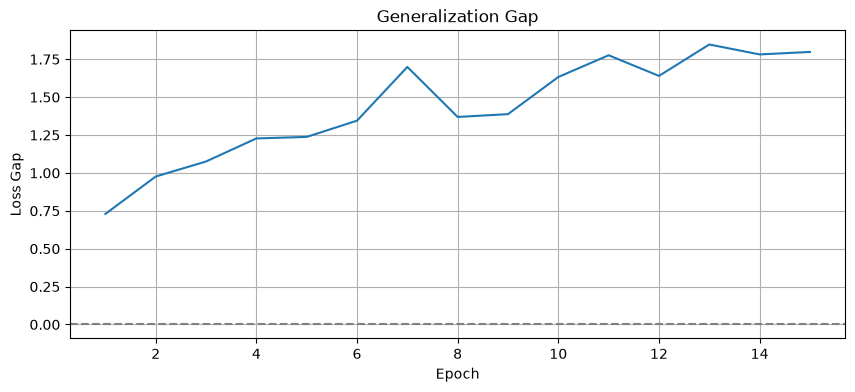

In [ ]:
loss_gap = np.array(val_loss_list) - np.array(tr_loss_list)

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(loss_gap) + 1), loss_gap)
plt.axhline(y=0, color='gray', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss Gap')
plt.title('Generalization Gap')
plt.grid()
plt.show()  # 3번째 epoch에서 모델 성능이 가장 뛰어났음을 확인

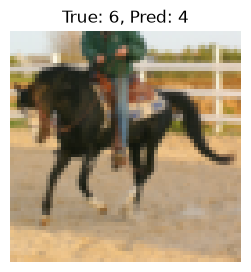

In [ ]:
load_model.eval()

x_batch, y_batch = next(iter(test_DL))

idx = 0

image = x_batch[idx:idx+1].to(device)
true_label = y_batch[idx].item()

with torch.no_grad():
    y_hat = load_model(image)
    pred_label = y_hat.argmax(dim=1).item()

plt.figure(figsize=(3, 3))
plt.imshow(image[0].cpu().permute(1, 2, 0))
plt.title(f'True: {true_label}, Pred: {pred_label}')
plt.axis('off')
plt.show()

In [ ]:
load_model.eval()

with torch.no_grad():

    feature_map1 = load_model.conv1(image)

    feature_map2 = load_model.conv2(
        load_model.maxpool1(feature_map1)
    )

    feature_map3 = load_model.conv3(
        load_model.maxpool2(feature_map2)
    )

print('Feature Map 1:', feature_map1.shape)
print('Feature Map 2:', feature_map2.shape)
print('Feature Map 3:', feature_map3.shape)

Feature Map 1: torch.Size([1, 32, 64, 64])
Feature Map 2: torch.Size([1, 64, 32, 32])
Feature Map 3: torch.Size([1, 128, 16, 16])


In [ ]:
def plot_feature_maps(feature_map, title, n_cols=8):

    feature_map = feature_map[0].detach().cpu()

    n_channels = feature_map.shape[0]
    n_rows = (n_channels + n_cols - 1) // n_cols

    plt.figure(figsize=(n_cols * 2, n_rows * 2))

    for i in range(n_channels):
        plt.subplot(n_rows, n_cols, i+1)
        plt.imshow(feature_map[i], cmap='viridis')
        plt.title(f'Ch {i}')
        plt.axis('off')

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

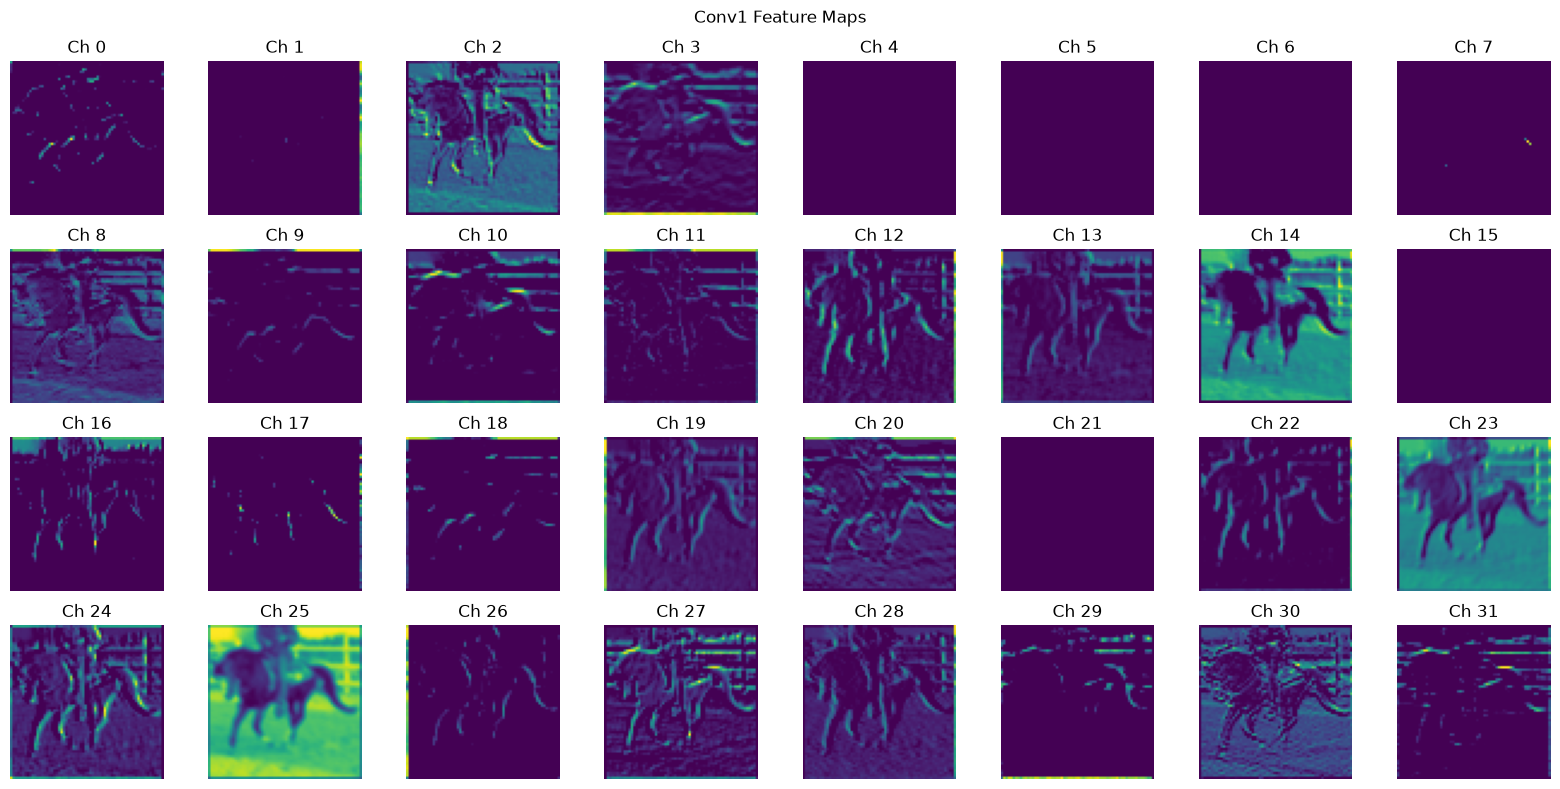

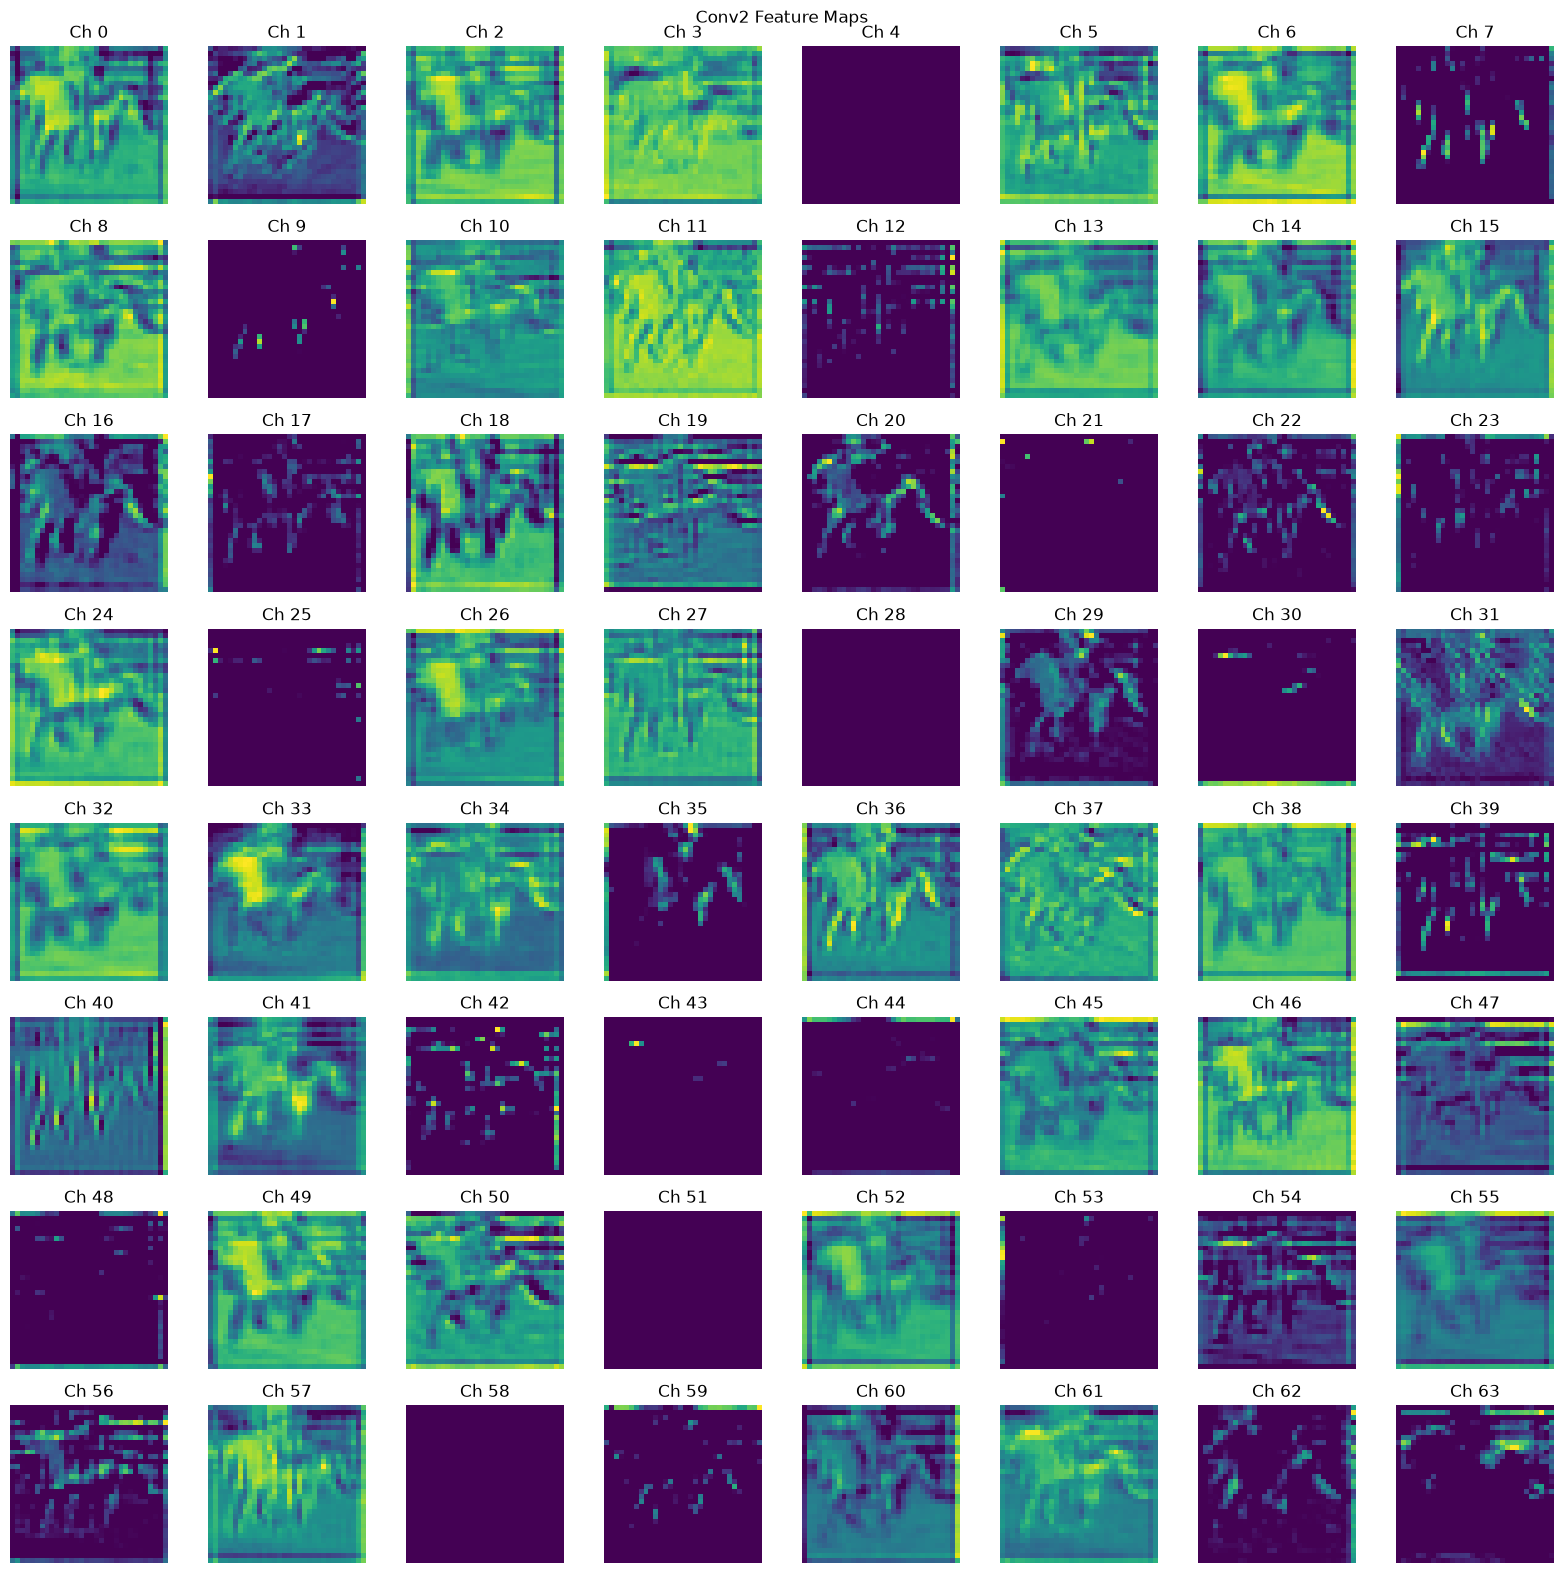

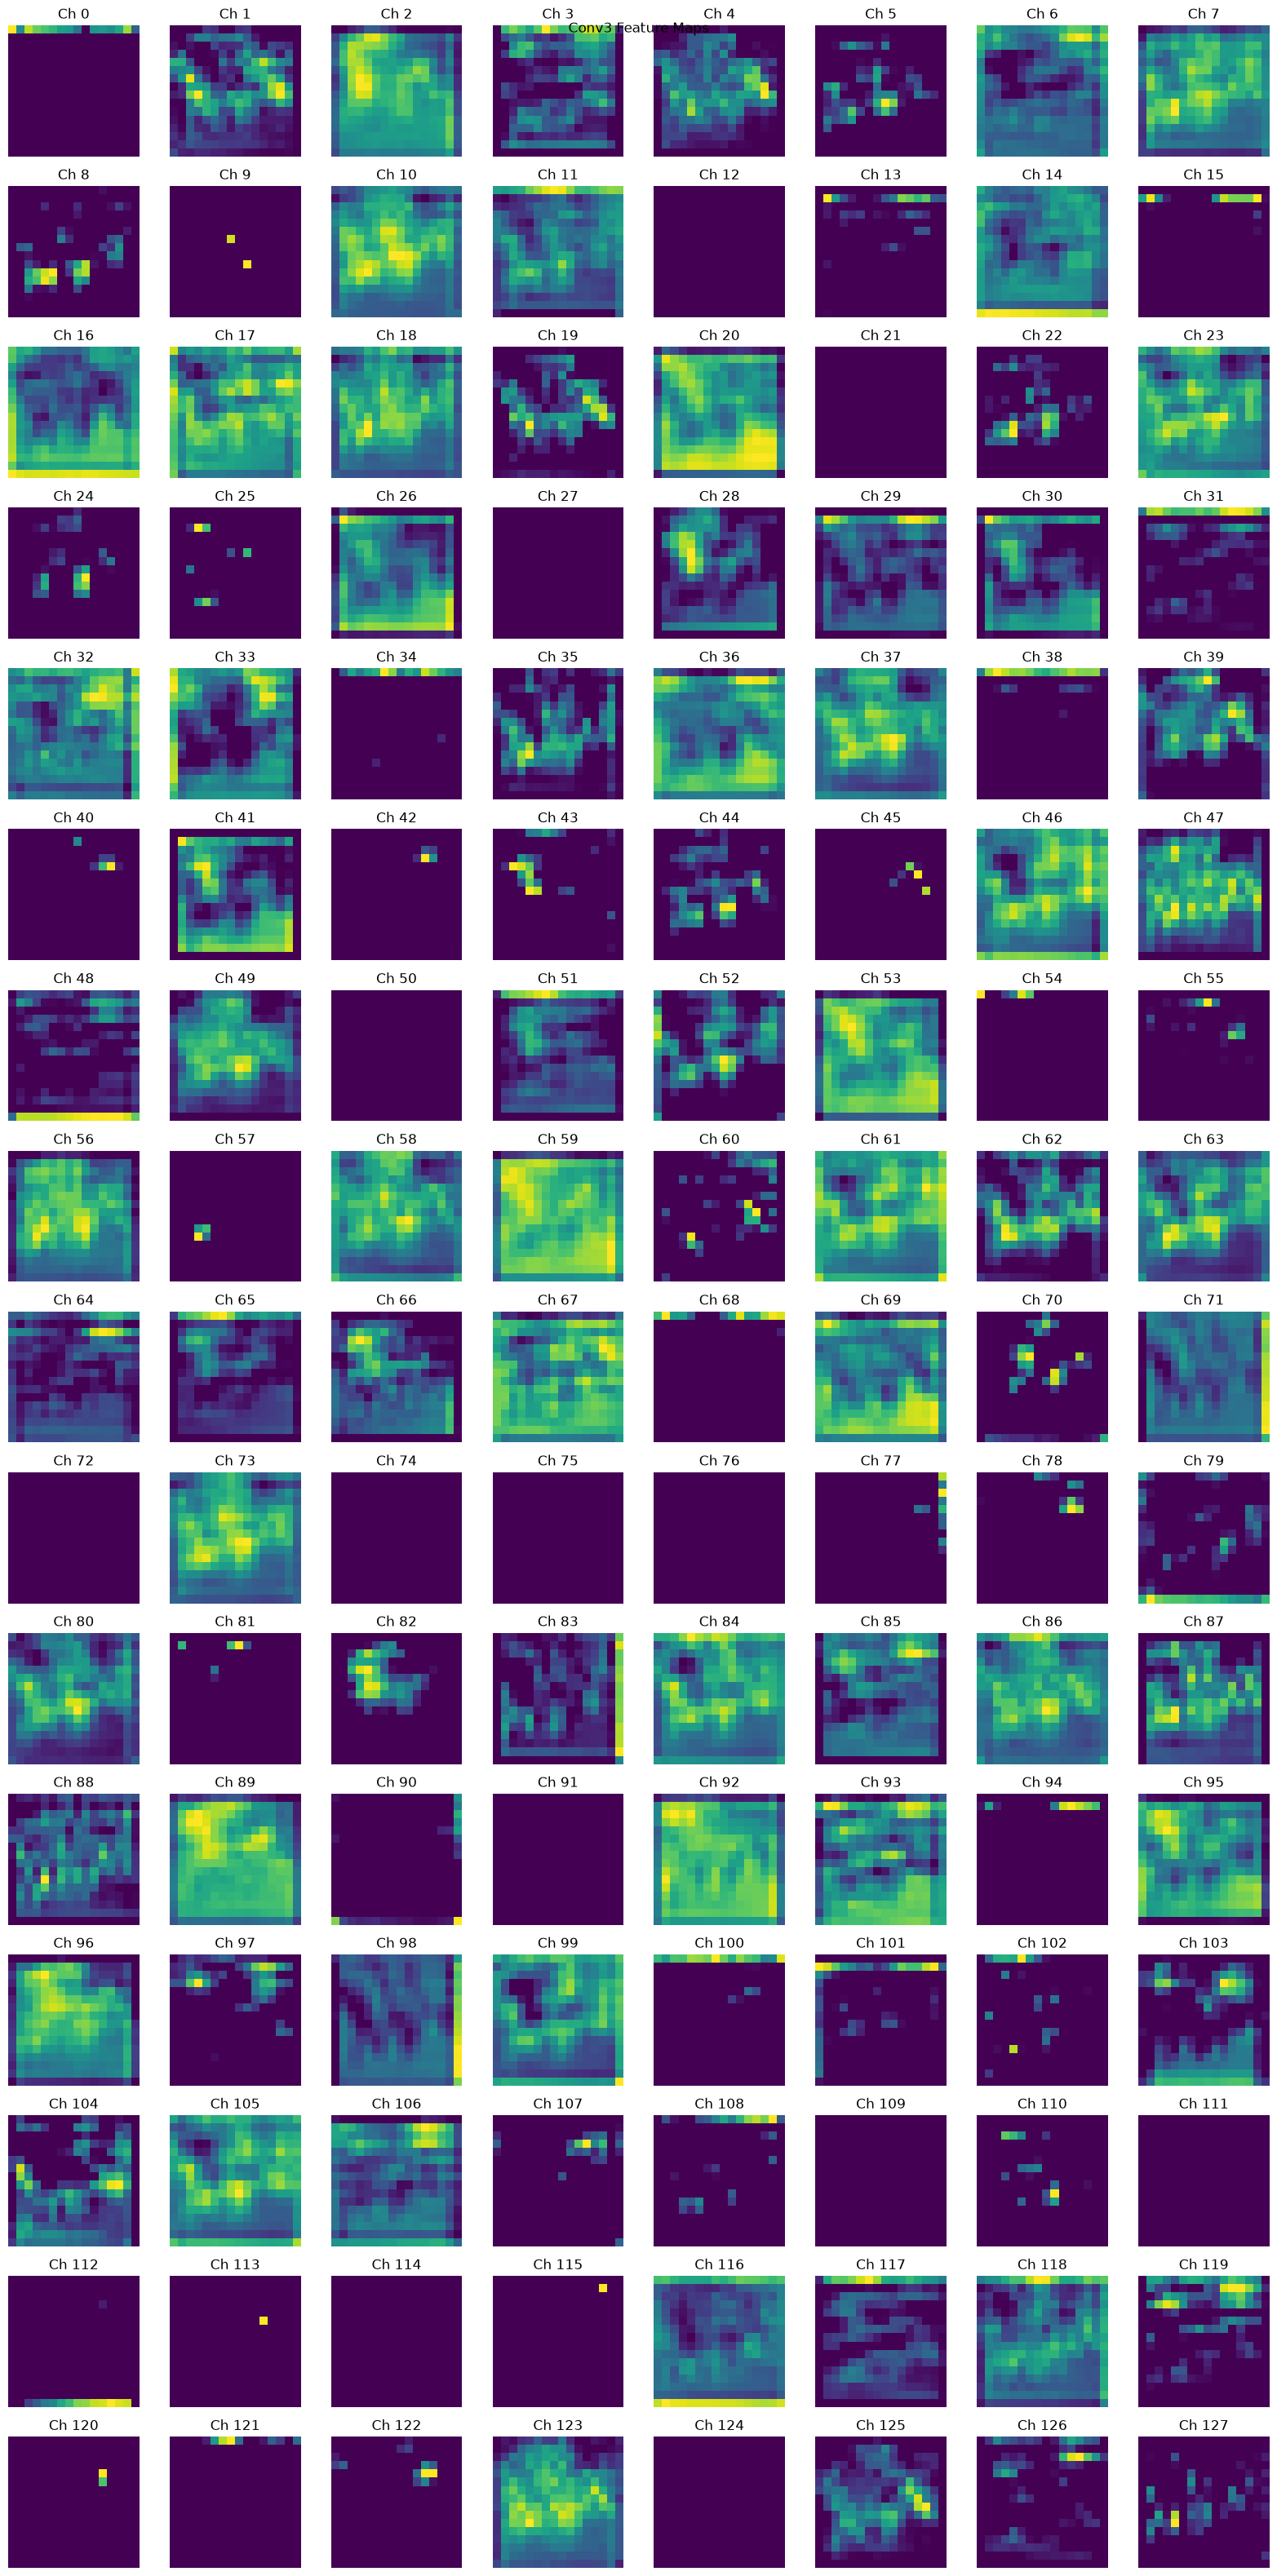

In [97]:
plot_feature_maps(feature_map1, 'Conv1 Feature Maps')
plot_feature_maps(feature_map2, 'Conv2 Feature Maps')
plot_feature_maps(feature_map3, 'Conv3 Feature Maps')

In [ ]:
def grad_cam(model, image, target_layer, target_class=None):

    model.eval()

    feature_maps = {}
    gradients = {}

    # 1. Feature Map 및 Gradient 수집
    def save_activation(module, inputs, output):
        feature_maps['value'] = output.detach()

        def save_gradient(grad):
            gradients['value'] = grad.detach()

        output.register_hook(save_gradient)

    # 2. Forward Hook 등록
    handle = target_layer.register_forward_hook(save_activation)

    try:
        with torch.enable_grad():

            image = image.detach().requires_grad_(True)

            # 3. Forward
            model.zero_grad(set_to_none=True)

            y_hat = model(image)
            pred_class = y_hat.argmax(dim=1).item()

            if target_class is None:
                target_class = pred_class

            # 4. 특정 클래스의 logit 선택
            score = y_hat[0, target_class]

            # 5. Backward
            score.backward()

            # 6. Feature Map과 Gradient 불러오기
            A = feature_maps['value']
            G = gradients['value']

            # 7. 채널별 Gradient 평균
            weights = G.mean(dim=(2, 3), keepdim=True)

            # 8. 가중합 및 ReLU
            cam = (weights * A).sum(dim=1, keepdim=True)
            cam = F.relu(cam)

            # 9. 원본 이미지 크기로 확대
            cam = F.interpolate(
                cam,
                size=image.shape[2:],
                mode='bilinear',
                align_corners=False
            )

            # 10. Heatmap 정규화
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-8)

            cam = cam[0, 0].detach().cpu()

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)

    return cam, pred_class

In [ ]:
cam, pred_label = grad_cam(
    model=load_model,
    image=image,
    target_layer=load_model.conv3
)

print('True Label:', true_label)
print('Pred Label:', pred_label)
print('CAM Shape :', cam.shape)

True Label: 6
Pred Label: 4
CAM Shape : torch.Size([64, 64])


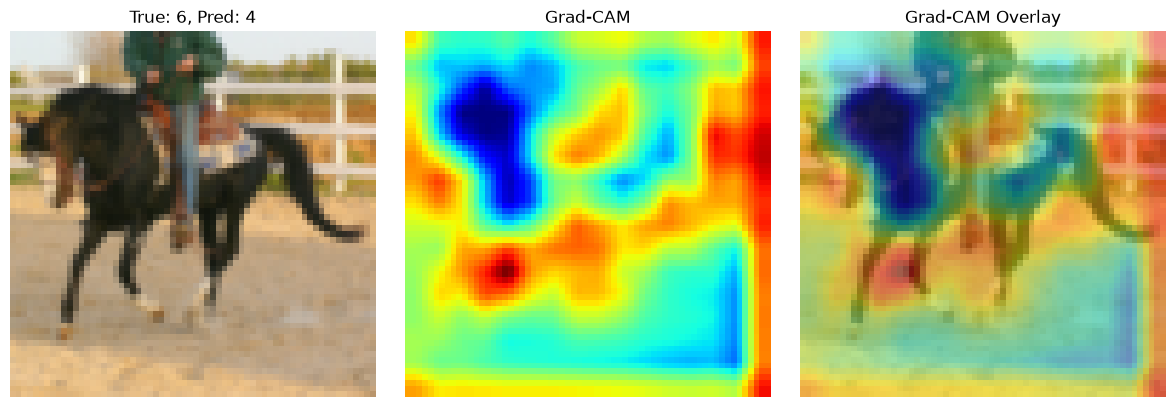

In [ ]:
def plot_grad_cam(image, cam, true_label, pred_label):

    img = image[0].detach().cpu().permute(1, 2, 0)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    # 원본 이미지
    ax[0].imshow(img)
    ax[0].set_title(f'True: {true_label}, Pred: {pred_label}')

    # Heatmap
    ax[1].imshow(cam, cmap='jet', vmin=0, vmax=1)
    ax[1].set_title('Grad-CAM')

    # Overlay
    ax[2].imshow(img)
    ax[2].imshow(
        cam,
        cmap='jet',
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    ax[2].set_title('Grad-CAM Overlay')

    for a in ax:
        a.axis('off')

    plt.tight_layout()
    plt.show()

plot_grad_cam(image, cam, true_label, pred_label)